<a href="https://colab.research.google.com/github/amandarcp78-sudo/ORES5160-2026-x2/blob/main/Week_11_A_Alberino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import csv

file_path = 'est2018-pop-res.csv'

with open(file_path, mode='r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for i in range(5):
        try:
            row = next(reader)
            print(row)
        except StopIteration:
            break

['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']
['010', '0', '0', '00', 'United States', '327167434', '253768092', '77.6']
['040', '3', '6', '01', 'Alabama', '4887871', '3798031', '77.7']
['040', '4', '9', '02', 'Alaska', '737438', '553622', '75.1']
['040', '4', '8', '04', 'Arizona', '7171646', '5528989', '77.1']


In [17]:
import pandas as pd

df_pop = pd.read_csv(file_path, encoding='utf-8')

print('DataFrame Shape:', df_pop.shape)

print('\nColumn Names:', df_pop.columns.tolist())

DataFrame Shape: (53, 8)

Column Names: ['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']


In [19]:
states_df = df_pop[df_pop['SUMLEV'].astype(int) == 40].copy()

states_df['POPESTIMATE2018'] = pd.to_numeric(states_df['POPESTIMATE2018'])

top_5_states = states_df[['NAME', 'POPESTIMATE2018']].sort_values(by='POPESTIMATE2018', ascending=False).head(5)

print("The column representing total population is 'POPESTIMATE2018'.")
print('\nTop 5 Most Populous States:')
display(top_5_states)

The column representing total population is 'POPESTIMATE2018'.

Top 5 Most Populous States:


,NAME,POPESTIMATE2018
5,California,39557045
44,Texas,28701845
10,Florida,21299325
33,New York,19542209
39,Pennsylvania,12807060


In [20]:
average_pop = states_df['POPESTIMATE2018'].mean()
print(f'Average population across all states: {average_pop:,.2f}')

Average population across all states: 6,353,126.67


In [23]:
region_pop = states_df.groupby('REGION')['POPESTIMATE2018'].sum().reset_index()

region_map = {'1': 'Northeast', '2': 'Midwest', '3': 'South', '4': 'West'}
region_pop['REGION_NAME'] = region_pop['REGION'].astype(str).map(region_map).fillna('Other/Unknown')

highest_region = region_pop.sort_values(by='POPESTIMATE2018', ascending=False).iloc[0]
print(f"The region with the highest total population is Region {highest_region['REGION']} ({highest_region['REGION_NAME']}) with {highest_region['POPESTIMATE2018']:,} people.\n")

display(region_pop)

The region with the highest total population is Region 3 (South) with 124,753,948 people.



,REGION,POPESTIMATE2018,REGION_NAME
0,1,56111079,Northeast
1,2,68308744,Midwest
2,3,124753948,South
3,4,77993663,West
4,X,3195153,Other/Unknown


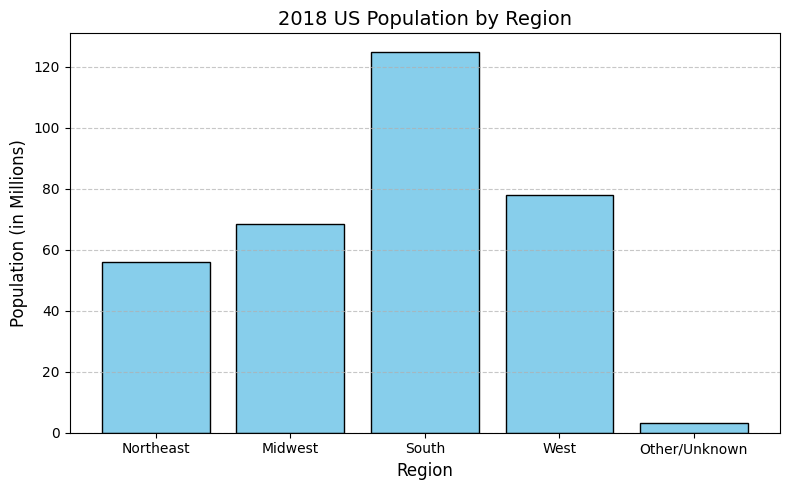

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(region_pop['REGION_NAME'].fillna('Unknown'), region_pop['POPESTIMATE2018'] / 1e6, color='skyblue', edgecolor='black')

plt.title('2018 US Population by Region', fontsize=14)
plt.xlabel('Region', fontsize=12)
plt.ylabel('Population (in Millions)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [27]:
import json

patient_data = {
    "resourceType": "Patient",
    "id": "example",
    "active": True,
    "name": [
        {
            "use": "official",
            "family": "Chalmers",
            "given": ["Peter", "James"]
        }
    ],
    "telecom": [
        {
            "system": "phone",
            "value": "(03) 5555 6473",
            "use": "work"
        },
        {
            "system": "phone",
            "value": "(03) 3410 5613",
            "use": "mobile"
        },
        {
            "system": "phone",
            "value": "(03) 8965 2214",
            "use": "home"
        }
    ],
    "gender": "male",
    "birthDate": "1974-12-25",
    "address": [
        {
            "use": "home",
            "line": ["534 Erewhon St"],
            "city": "Pleasantville",
            "state": "Vic",
            "postalCode": "3999"
        }
    ]
}

with open('patient.json', 'w', encoding='utf-8') as f:
    json.dump(patient_data, f, indent=4)

print("patient.json has been written successfully.")

patient.json has been written successfully.


In [28]:
with open('patient.json', 'r', encoding='utf-8') as f:
    patient_dict = json.load(f)

official_name = None
for name in patient_dict.get('name', []):
    if name.get('use') == 'official':
        given_names = " ".join(name.get('given', []))
        family_name = name.get('family', '')
        official_name = f"{given_names} {family_name}"
        break

if not official_name and patient_dict.get('name'):
    name = patient_dict['name'][0]
    given_names = " ".join(name.get('given', []))
    family_name = name.get('family', '')
    official_name = f"{given_names} {family_name}"

gender = patient_dict.get('gender', 'N/A')
birth_date = patient_dict.get('birthDate', 'N/A')

address_info = "N/A"
if patient_dict.get('address'):
    addr = patient_dict['address'][0]
    city = addr.get('city', 'N/A')
    state = addr.get('state', 'N/A')
    zip_code = addr.get('postalCode', 'N/A')
    address_info = f"{city}, {state} {zip_code}"

print("Patient Information:")
print(f"- Full Official Name: {official_name}")
print(f"- Gender: {gender}")
print(f"- Birth Date: {birth_date}")
print(f"- Current Address: {address_info}\n")

phone_telecoms = [t for t in patient_dict.get('telecom', []) if t.get('system') == 'phone']
num_phones = len(phone_telecoms)
phone_details = [f"{t.get('use', 'unknown')}: {t.get('value')}" for t in phone_telecoms]

print(f"Phone Count & Types:")
print(f"- Number of phone numbers: {num_phones}")
for detail in phone_details:
    print(f"  * {detail}")

Patient Information:
- Full Official Name: Peter James Chalmers
- Gender: male
- Birth Date: 1974-12-25
- Current Address: Pleasantville, Vic 3999

Phone Count & Types:
- Number of phone numbers: 3
  * work: (03) 5555 6473
  * mobile: (03) 3410 5613
  * home: (03) 8965 2214
